Urządzenie: cpu
Pobieranie CIFAR-10...


100%|██████████| 170M/170M [00:13<00:00, 12.4MB/s]


Trening: 45000
Walidacja: 5000
Test: 10000


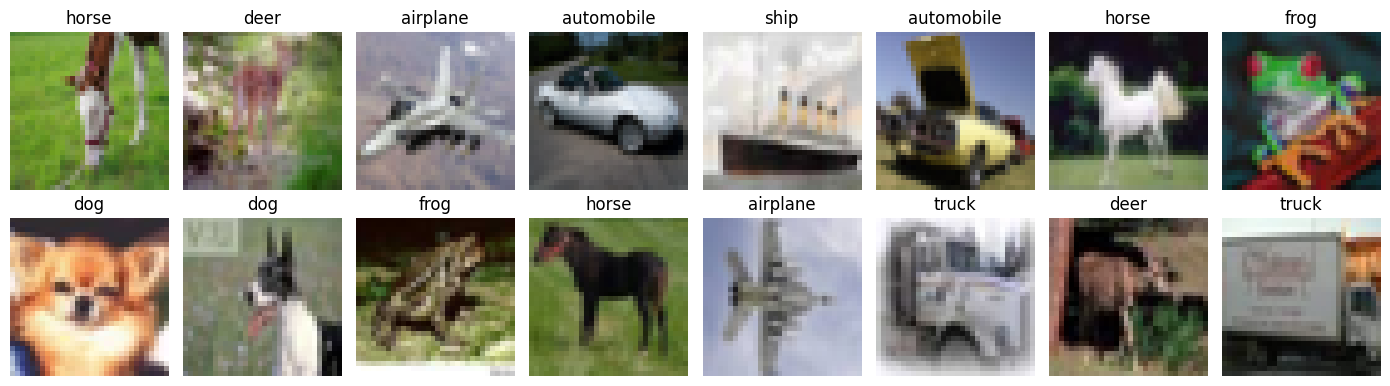


========== TRENING MLP ==========
Epoka 1/3 | Train: 48.23% | Val: 46.14%
Epoka 2/3 | Train: 53.57% | Val: 49.52%
Epoka 3/3 | Train: 56.90% | Val: 49.88%

========== TRENING CNN ==========
Epoka 1/3 | Train: 59.18% | Val: 59.18%
Epoka 2/3 | Train: 64.43% | Val: 62.82%
Epoka 3/3 | Train: 70.92% | Val: 68.44%

========== TABELA WYNIKÓW ==========
Model       Parametry      Train        Val       Test        Gap       Czas
MLP         1,707,274     56.90%     49.88%     49.42%      7.02%      87.3s
CNN         1,070,986     70.92%     68.44%     67.98%      2.48%     330.4s

CNN – część splotowa: 19584
CNN – głowica: 1051402


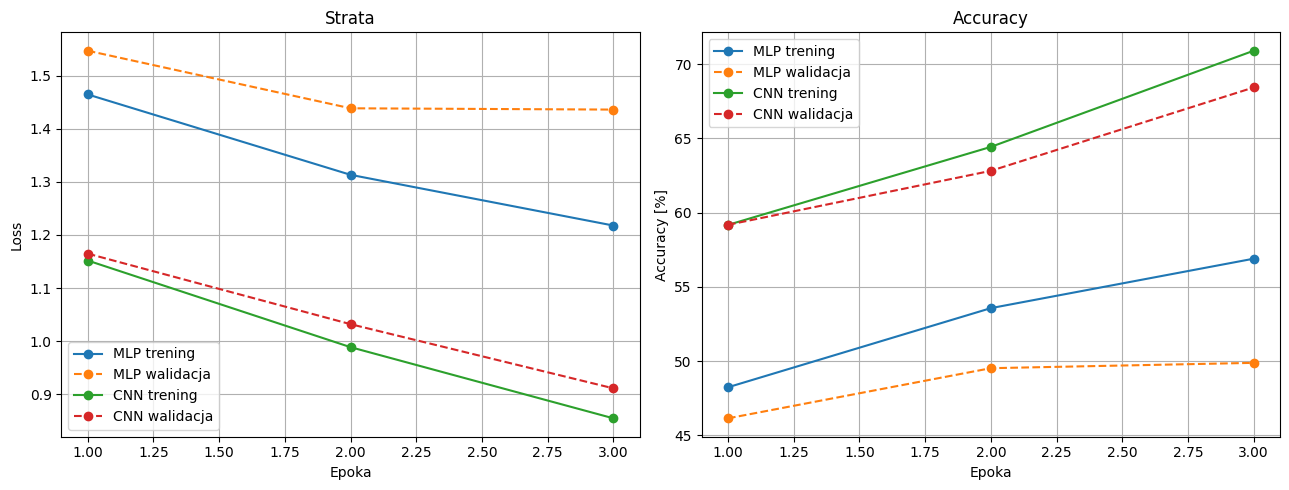

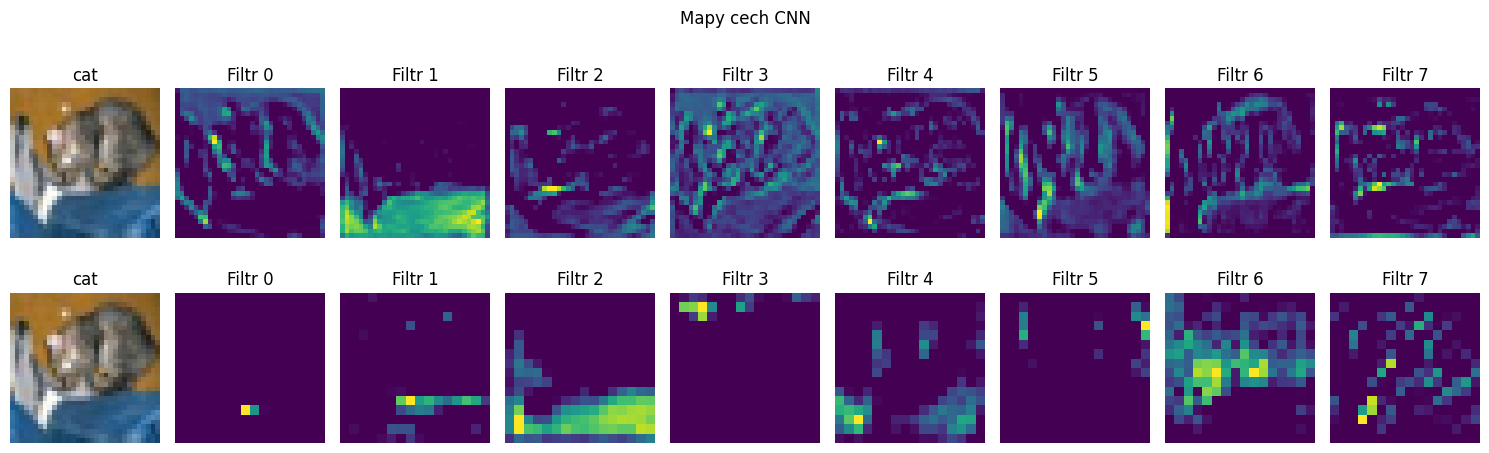


========== LICZBA FILTRÓW ==========

Filtry: 16/32


In [ ]:



import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import random
import time
import copy



CFG = {
    "epochs": 3,
    "lr": 0.001,
    "batch_size": 128,
    "n_val": 5000,
    "seed": 42
}

random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Urządzenie:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))



mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Pobieranie CIFAR-10...")

train_full = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True,
    transform=transform
)

test_ds = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True,
    transform=transform
)

classes = train_full.classes

g = torch.Generator().manual_seed(CFG["seed"])
indices = torch.randperm(50000, generator=g).tolist()

val_idx = indices[:5000]
train_idx = indices[5000:]

train_ds = Subset(train_full, train_idx)
val_ds = Subset(train_full, val_idx)

train_dl = DataLoader(
    train_ds, batch_size=CFG["batch_size"],
    shuffle=True, num_workers=0
)

val_dl = DataLoader(
    val_ds, batch_size=256,
    shuffle=False, num_workers=0
)

test_dl = DataLoader(
    test_ds, batch_size=256,
    shuffle=False, num_workers=0
)

print("Trening:", len(train_ds))
print("Walidacja:", len(val_ds))
print("Test:", len(test_ds))



mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)

def denorm(img):
    return ((img.cpu() * std_t + mean_t)
            .clamp(0, 1).permute(1, 2, 0).numpy())

xb, yb = next(iter(train_dl))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for ax, img, label in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img))
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()



class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.net(x)



def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )



class SimpleCNN(nn.Module):
    def __init__(self, c1=32, c2=64):
        super().__init__()

        self.features = nn.Sequential(
            block(3, c1),
            block(c1, c2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c2 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters()
               if p.requires_grad)


criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            out = model(x)
            loss = criterion(out, y)

            total_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

    return total_loss / total, correct / total



def fit(model):
    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=CFG["lr"]
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_acc = -1
    best_epoch = 0
    best_state = None

    start = time.time()

    for epoch in range(1, CFG["epochs"] + 1):

        model.train()
        total_loss = 0
        total = 0

        for x, y in train_dl:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            out = model(x)
            loss = criterion(out, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * y.size(0)
            total += y.size(0)

        train_loss, train_acc = evaluate(model, train_dl)
        val_loss, val_acc = evaluate(model, val_dl)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoka {epoch}/{CFG['epochs']} | "
            f"Train: {train_acc*100:.2f}% | "
            f"Val: {val_acc*100:.2f}%"
        )

    elapsed = time.time() - start

    model.load_state_dict(best_state)

    return {
        "model": model,
        "hist": history,
        "best": {
            "val_acc": best_acc,
            "epoch": best_epoch
        },
        "train_time": elapsed
    }


print("\n========== TRENING MLP ==========")
res_mlp = fit(MLP())


print("\n========== TRENING CNN ==========")
res_cnn = fit(SimpleCNN())


rows = []

for name, result in [("MLP", res_mlp), ("CNN", res_cnn)]:

    model = result["model"]
    h = result["hist"]
    epoch = result["best"]["epoch"] - 1

    _, test_acc = evaluate(model, test_dl)

    rows.append({
        "model": name,
        "params": count_params(model),
        "train": h["train_acc"][epoch],
        "val": h["val_acc"][epoch],
        "test": test_acc,
        "gap": h["train_acc"][epoch] - h["val_acc"][epoch],
        "time": result["train_time"]
    })

print("\n========== TABELA WYNIKÓW ==========")

print(f"{'Model':<8} {'Parametry':>12} {'Train':>10} "
      f"{'Val':>10} {'Test':>10} {'Gap':>10} {'Czas':>10}")

for r in rows:
    print(
        f"{r['model']:<8} "
        f"{r['params']:>12,} "
        f"{r['train']*100:>9.2f}% "
        f"{r['val']*100:>9.2f}% "
        f"{r['test']*100:>9.2f}% "
        f"{r['gap']*100:>9.2f}% "
        f"{r['time']:>9.1f}s"
    )

print("\nCNN – część splotowa:",
      count_params(res_cnn["model"].features))
print("CNN – głowica:",
      count_params(res_cnn["model"].classifier))


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, result in [("MLP", res_mlp), ("CNN", res_cnn)]:
    h = result["hist"]
    ep = range(1, CFG["epochs"] + 1)

    axes[0].plot(ep, h["train_loss"], marker="o",
                 label=f"{name} trening")
    axes[0].plot(ep, h["val_loss"], marker="o",
                 linestyle="--", label=f"{name} walidacja")

    axes[1].plot(ep, [v*100 for v in h["train_acc"]],
                 marker="o", label=f"{name} trening")
    axes[1].plot(ep, [v*100 for v in h["val_acc"]],
                 marker="o", linestyle="--",
                 label=f"{name} walidacja")

axes[0].set_title("Strata")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy [%]")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()



cnn = res_cnn["model"].eval()
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)

with torch.no_grad():
    maps1 = torch.relu(cnn.features[0][0](x))[0].cpu()
    after1 = cnn.features[0](x)
    maps2 = torch.relu(cnn.features[1][0](after1))[0].cpu()

fig, axes = plt.subplots(2, 9, figsize=(15, 5))

for row, maps in enumerate([maps1, maps2]):
    axes[row, 0].imshow(denorm(img))
    axes[row, 0].set_title(classes[label])
    axes[row, 0].axis("off")

    for i, ax in enumerate(axes[row, 1:]):
        ax.imshow(maps[i], cmap="viridis")
        ax.set_title(f"Filtr {i}")
        ax.axis("off")

plt.suptitle("Mapy cech CNN")
plt.tight_layout()
plt.show()


filter_results = []

print("\n========== LICZBA FILTRÓW ==========")

for c1, c2 in [(16, 32), (32, 64), (64, 128)]:

    print(f"\nFiltry: {c1}/{c2}")

    result = fit(SimpleCNN(c1, c2))

    filter_results.append((
        f"{c1}/{c2}",
        count_params(result["model"]),
        result["best"]["val_acc"],
        result["train_time"]
    ))

print("\nFiltry | Parametry | Accuracy wal. | Czas")

for r in filter_results:
    print(
        f"{r[0]:>8} | {r[1]:>10,} | "
        f"{r[2]*100:>10.2f}% | {r[3]:.1f}s"
    )


class CNNDepth(nn.Module):
    def __init__(self, n_blocks=2):
        super().__init__()

        channels = [32, 64, 128]
        layers = []
        cin = 3

        for cout in channels[:n_blocks]:
            layers.append(block(cin, cout))
            cin = cout

        self.features = nn.Sequential(*layers)

        size = 32 // (2 ** n_blocks)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(cin * size * size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


depth_results = []

print("\n========== LICZBA BLOKÓW ==========")

for n in [1, 2, 3]:

    print(f"\nLiczba bloków: {n}")

    result = fit(CNNDepth(n))

    depth_results.append((
        n,
        count_params(result["model"]),
        result["best"]["val_acc"],
        result["train_time"]
    ))

print("\nBloki | Parametry | Accuracy wal. | Czas")

for r in depth_results:
    print(
        f"{r[0]:>5} | {r[1]:>10,} | "
        f"{r[2]*100:>10.2f}% | {r[3]:.1f}s"
    )


best = max(rows, key=lambda x: x["val"])

print("\n========================================")
print("PODSUMOWANIE LABORATORIUM 04")
print("========================================")

print("Urządzenie:", device)
print("Najlepszy model:", best["model"])
print("Accuracy walidacyjne:", round(best["val"]*100, 2), "%")

for r in rows:
    print(
        f"{r['model']}: test accuracy "
        f"{r['test']*100:.2f}%"
    )

print("\nWSZYSTKIE EKSPERYMENTY ZAKOŃCZONE!")


